# Photoneo PhoXi 3D M — Capture Test

Connects to the live Photoneo PhoXi 3D M scanner, triggers a single frame, and displays the texture and depth map with matplotlib.

**Prerequisites:**
- `pip install phoxi-api` (already installed in cnos2)
- PhoXi Control running (`/usr/bin/PhoXiControl`)
- Scanner discovered in PhoXi Control's device list — if network discovery doesn't find it, use `Tools → Add Device via Address` with the scanner's IP

**Depth convention:** PhoXi DepthMap is in **millimetres** — `depth_scale = 1.0`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

K:
[[2.82421655e+03 0.00000000e+00 1.25717993e+03]
 [0.00000000e+00 2.82397192e+03 1.00944037e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
RGB:   (480, 640, 3)
Depth: (480, 640)  range 0–986 mm


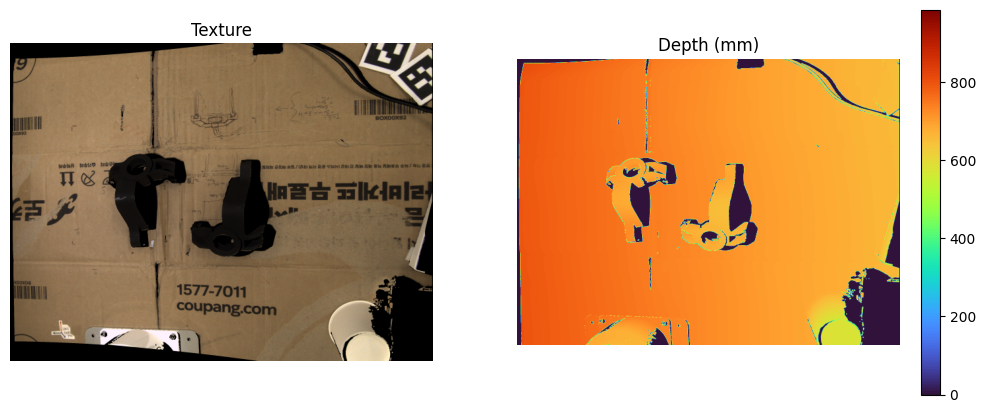

In [2]:
DEPTH_SCALE = 1.0  # PhoXi DepthMap is already in mm

from phoxi_api import PhoXiControl, PhoXiDevice

phc = PhoXiControl()
device_id = next(
    d["id"] for d in phc.get_device_list(refresh=True)
    if d["type"] == "PhoXi3DScan" and not d["file_camera"]
)

with phc.connect(device_id) as device:
    device.set_trigger_mode(PhoXiDevice.TriggerMode.SOFTWARE)
    device.set_frame_settings({"DepthMap": True, "Texture": True, "ColorCameraImage": True})
    device.start_acquisition()
    frame = device.get_frame(frame_id=device.trigger_frame(wait_grabbing_end=True), timeout_ms=60_000)

K = np.array(frame.Info["CameraMatrix"], dtype=np.float32).reshape(3, 3)
depth = np.array(frame.DepthMap, dtype=np.float32).squeeze()
texture = np.array(frame.Texture).squeeze()
# rgb = np.array(frame.ColorCameraImage).squeeze()
rgb = np.stack([texture] * 3, axis=-1) if texture.ndim == 2 else texture
rgb = (rgb / rgb.max() * 255).clip(0, 255).astype(np.uint8)

rgb = cv2.resize(rgb, (640, 480), interpolation=cv2.INTER_AREA)
depth = cv2.resize(depth, (640, 480), interpolation=cv2.INTER_AREA)

print(f"K:\n{K}")
print(f"RGB:   {rgb.shape}")
print(f"Depth: {depth.shape}  range {depth.min():.0f}–{depth.max():.0f} mm")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb); axes[0].set_title("Texture"); axes[0].axis("off")
im = axes[1].imshow(depth, cmap="turbo"); axes[1].set_title("Depth (mm)"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.show()


In [3]:
import torch

from src.sam6d import SAM6D

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

CAD_PATHS = [
    "/home/joon/Downloads/cad_files/steering_knuckle/steering-knuckle-thunder-truck-r1-r.stl",
]
MODEL_IDS = ["steering_knuckle"]
TEMPLATE_DIRS = ["./sam6d_templates_steering_knuckle"]
MESH_COLORS = [(int(0.01*255), int(0.01*255), int(0.01*255))]   # steering_knuckle — dark warm gray  (~22% luminance)
FLAT_SHADING = True
CAD_PATHS_BY_ID = dict(zip(MODEL_IDS, CAD_PATHS))


/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Using device: cuda


In [4]:
model = SAM6D(
    cad_path=CAD_PATHS,
    model_ids=MODEL_IDS,
    template_dirs=TEMPLATE_DIRS,
    device=DEVICE,

    sam_model_type="vit_h",
    stability_score_thresh=0.97,

    reset_templates=False,
    mesh_color=MESH_COLORS,
    flat_shading=FLAT_SHADING,
    roughness=0.9,
    metallic=0.0,
    light_energy=1100,

    det_score_thresh=0.35,
    confidence_thresh=0.3,
    visible_thred=0.5,
    n_template_view=42,
    min_component_area_ratio=0.005,
    mask_overlap_thresh=0.2,
    pose_score_thresh=0.3,

    half_precision=False,
)


load pre-trained checkpoint from: /home/joon/Projects/cnos/checkpoints/mae_pretrain_vit_base.pth


In [5]:
results = model(rgb, depth, K, depth_scale=DEPTH_SCALE)

N = len(results["poses"])
print(f"Detections: {N}")
for i in range(N):
    print(
        f"[{i}]  model_id={results['model_ids'][i]!r:22s}"
        f"  ism={results['ism_scores'][i]:.3f}"
        f"  pose_score={results['pose_scores'][i]:.3f}"
    )


Detections: 2
[0]  model_id='steering_knuckle'      ism=0.421  pose_score=0.370
[1]  model_id='steering_knuckle'      ism=0.570  pose_score=0.503


In [6]:
import json
from datetime import datetime
from scipy.spatial.transform import Rotation

detections = []
for i, pose in enumerate(results["poses"]):
    x, y, z = pose["t"]
    roll, pitch, yaw = Rotation.from_matrix(pose["R"]).as_euler("xyz", degrees=True)
    det = {
        "model_id": results["model_ids"][i],
        "xyz_mm": [float(x), float(y), float(z)],
        "rpy_deg": [float(roll), float(pitch), float(yaw)],
        "score": float(pose["score"]),
    }
    detections.append(det)
    print(
        f"[{i}] {det['model_id']:16s}"
        f"  XYZ(mm)=({x:8.1f}, {y:8.1f}, {z:8.1f})"
        f"  RPY(deg)=({roll:7.1f}, {pitch:7.1f}, {yaw:7.1f})"
        f"  score={det['score']:.3f}"
    )

out_path = f"/home/joon/test/detections_{datetime.now():%Y%m%d_%H%M%S}.json"
with open(out_path, "w") as f:
    json.dump(detections, f, indent=2)
print(f"\nSaved {len(detections)} detection(s) to {out_path}")


[0] steering_knuckle  XYZ(mm)=(     5.4,    121.4,    255.3)  RPY(deg)=(   43.6,   -27.8,   137.2)  score=0.370
[1] steering_knuckle  XYZ(mm)=(  -443.6,   -473.7,   1116.8)  RPY(deg)=( -102.5,    54.7,  -138.7)  score=0.503

Saved 2 detection(s) to /home/joon/test/detections_20260709_160505.json


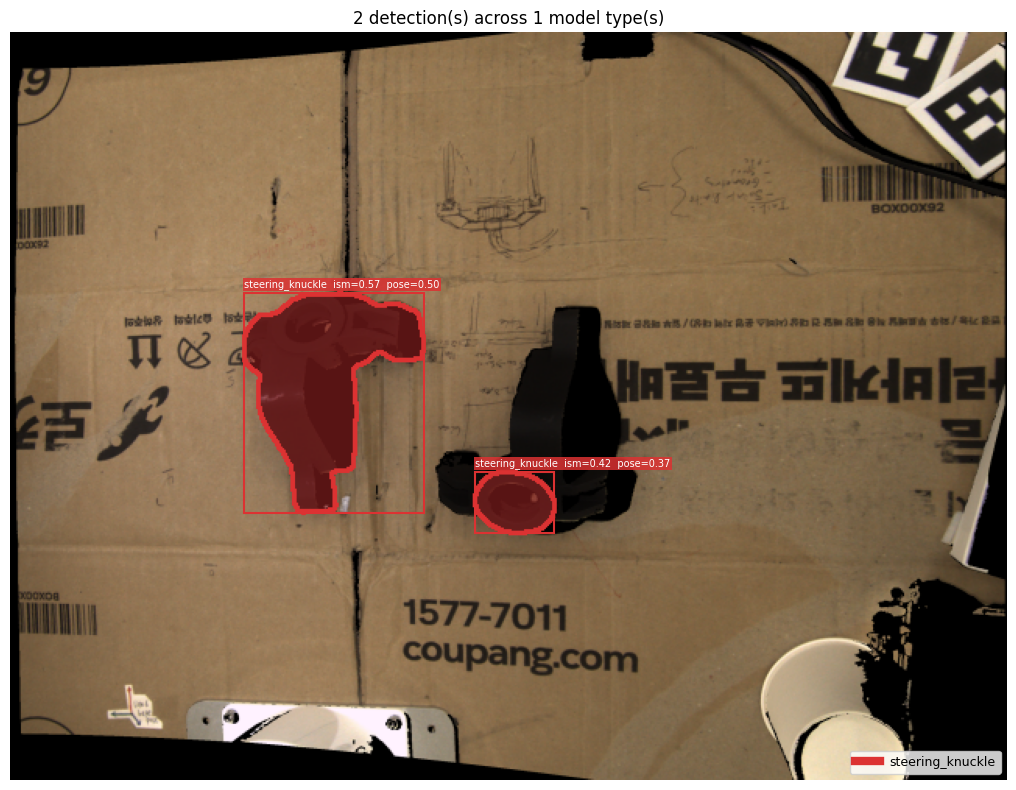

In [7]:
def visualize_multi_model_detections(rgb, results, alpha=0.4):
    import cv2

    MODEL_PALETTE = {
        "helical_gear":    np.array([102, 102, 102]),
        "carrier_flipper": np.array([ 50, 120, 240]),
        "carrier_gear":    np.array([  0,  89, 242]),
    }
    FALLBACK_COLORS = [
        np.array([220,  50,  50]),
        np.array([ 50, 200,  80]),
        np.array([180,  50, 220]),
        np.array([ 50, 220, 220]),
    ]

    masks       = results["masks"]
    boxes       = results["boxes"]
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]
    model_ids   = results.get("model_ids", ["unknown"] * len(masks))

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    unique_models = sorted(set(model_ids))
    color_map = {}
    fallback_idx = 0
    for mid in unique_models:
        if mid in MODEL_PALETTE:
            color_map[mid] = MODEL_PALETTE[mid]
        else:
            color_map[mid] = FALLBACK_COLORS[fallback_idx % len(FALLBACK_COLORS)]
            fallback_idx += 1

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        color = color_map[model_ids[i]]
        overlay[masks[i].astype(bool)] = (
            (1 - alpha) * overlay[masks[i].astype(bool)] + alpha * color
        )

    canvas = overlay.astype(np.uint8)
    for i in order:
        color = color_map[model_ids[i]]
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, color.tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s, mid) in enumerate(
        zip(boxes, ism_scores, pose_scores, model_ids)
    ):
        x1, y1, x2, y2 = box
        color = color_map[mid] / 255.0
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 4,
            f"{mid}  ism={ism_s:.2f}  pose={pose_s:.2f}",
            color="white", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.85, pad=1, edgecolor="none"),
        )

    for mid, color in color_map.items():
        ax.plot([], [], color=color / 255.0, linewidth=6, label=mid)
    ax.legend(loc="lower right", fontsize=9, framealpha=0.8)

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s) across {len(unique_models)} model type(s)")
    plt.tight_layout()
    plt.show()


visualize_multi_model_detections(rgb, results)


In [8]:
from src.foundationpose import FoundationPoseRefiner

fp = FoundationPoseRefiner(
    cad_path=CAD_PATHS,
    device=DEVICE,

    # Mesh units → metres conversion (1/1000 = mm→m, which is the default for STL/CAD files)
    mesh_scale=1/1000.0,   # STL units → metres (1/1000 for mm STL)

    # Refinement iterations: more = slower but more accurate
    est_refine_iter=5,    # for register() — first frame
    track_refine_iter=2,  # for track()    — subsequent frames

    # Detection filtering
    max_detections=4,   # None = refine all SAM-6D detections; int N = top-N by pose_score
    min_pose_score=0.0,    # skip SAM-6D detections with pose_score below this threshold

    debug=0,               # 0 = silent; ≥2 = saves debug renders to debug_dir

    # Memory management — uncomment to reduce VRAM usage
    # half_precision=True,  # fp16 weights for RefineNet + ScoreNet (~50% less VRAM)
    # lazy_load=True,       # defer loading RefineNet/ScoreNet until first refine_from_sam6d() call
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Warp 1.13.0 initialized:
   CUDA Toolkit 12.9, Driver 13.2
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA RTX A6000" (47 GiB, sm_86, mempool enabled)
   Kernel cache:
     /home/joon/.cache/warp/1.13.0


ModuleNotFoundError: No module named 'learning.datasets'

In [ ]:
print(results)

{'poses': [{'R': array([[-0.48755968, -0.29495823,  0.8217572 ],
       [ 0.6226348 , -0.7772703 ,  0.09042692],
       [ 0.6120553 ,  0.55574316,  0.56261694]], dtype=float32), 't': array([ 17.68225, 127.2631 , 245.23544], dtype=float32), 'score': 0.3375582695007324}], 'masks': array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(1, 480, 640)), 'boxes': array([[361, 230, 411, 276]]), 'ism_scores': array([0.38903734], dtype=float32), 'semantic_scores': array([0.33298966], dtype=float32), 'appe_scores': array([0.50217074], dtype=float32), 'geometric_scores': array([0.09219176], dtype=float32), 'visible_ratios': array([0.1923077], dtype=float32), 'best_template_ids': array([8]

In [ ]:
# Pass SAM-6D results directly — FoundationPose registers on each detection's mask.
# `results` is the dict returned by the SAM6D forward pass above.
refined = fp(rgb, depth, K, results, depth_scale=DEPTH_SCALE)

print(f"Refined {len(refined)} detection(s)\n")
for i, r in enumerate(refined):
    print(
        f"[{i}]  detection_idx={r['detection_idx']}"
        f"  sam6d_score={r['sam6d_score']:.3f}"
        f"  fp_score={r['fp_score']:.4f}"
    )
    print(f"     pose (4×4, translation in metres):")
    print(f"     {r['pose']}")

[_load_models()] FoundationPose models loaded.
[reset_object()] self.diameter:0.05311250320828683, vox_size:0.003
[reset_object()] self.pts:torch.Size([258, 3])
[reset_object()] reset done
[make_rotation_grid()] cam_in_obs:(42, 4, 4)
[make_rotation_grid()] rot_grid:(252, 4, 4)
[make_rotation_grid()] after cluster, rot_grid:(252, 4, 4)
[make_rotation_grid()] self.rot_grid: torch.Size([252, 4, 4])
[register()] Welcome
[register()] poses:(252, 4, 4)
[register()] after viewpoint, add_errs min:-1.0
/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)
[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.019999999552965164,

num original candidates = 252
num of pose after clustering: 252
Module Utils 9293bed load on device 'cuda:0' took 0.56 ms  (cached)


[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make

Refined 1 detection(s)

[0]  detection_idx=0  sam6d_score=0.338  fp_score=140.0312
     pose (4×4, translation in metres):
     [[ 0.18757215  0.06751702 -0.9799276  -0.2530117 ]
 [ 0.9599319  -0.22406113  0.16830693 -0.2265633 ]
 [-0.2082     -0.9722334  -0.1068394   1.2357509 ]
 [ 0.          0.          0.          1.        ]]


In [ ]:
print(results['poses'][0])
print(refined[0]['pose'])

{'R': array([[-0.48755968, -0.29495823,  0.8217572 ],
       [ 0.6226348 , -0.7772703 ,  0.09042692],
       [ 0.6120553 ,  0.55574316,  0.56261694]], dtype=float32), 't': array([ 17.68225, 127.2631 , 245.23544], dtype=float32), 'score': 0.3375582695007324}
[[ 0.18757215  0.06751702 -0.9799276  -0.2530117 ]
 [ 0.9599319  -0.22406113  0.16830693 -0.2265633 ]
 [-0.2082     -0.9722334  -0.1068394   1.2357509 ]
 [ 0.          0.          0.          1.        ]]
